Shape: (35846, 5)

Columns:
['Time (s)', 'Gyroscope x (rad/s)', 'Gyroscope y (rad/s)', 'Gyroscope z (rad/s)', 'Absolute (rad/s)']

First 5 rows:


,Time (s),Gyroscope x (rad/s),Gyroscope y (rad/s),Gyroscope z (rad/s),Absolute (rad/s)
0,0.011484,-0.073304,0.118508,0.032376,0.143059
1,0.013483,-0.073304,0.118508,0.032376,0.143059
2,0.015483,-0.073304,0.118508,0.032376,0.143059
3,0.017482,-0.073304,0.118508,0.032376,0.143059
4,0.019482,-0.073304,0.118508,0.032376,0.143059



Last 5 rows:


,Time (s),Gyroscope x (rad/s),Gyroscope y (rad/s),Gyroscope z (rad/s),Absolute (rad/s)
35841,71.672280,0.095906,0.136834,0.273668,0.320648
35842,71.674279,0.088575,0.128282,0.277333,0.318144
35843,71.676277,0.080634,0.111177,0.274889,0.307289
35844,71.678275,0.067806,0.087354,0.272446,0.294032
35845,71.680275,0.056200,0.062308,0.268781,0.281574



Duration: 71.68027457 seconds


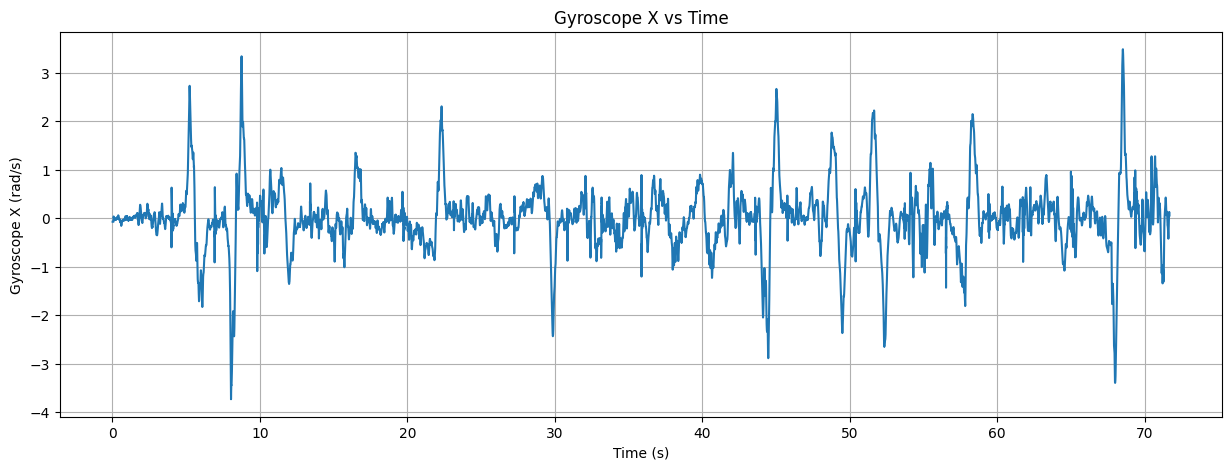

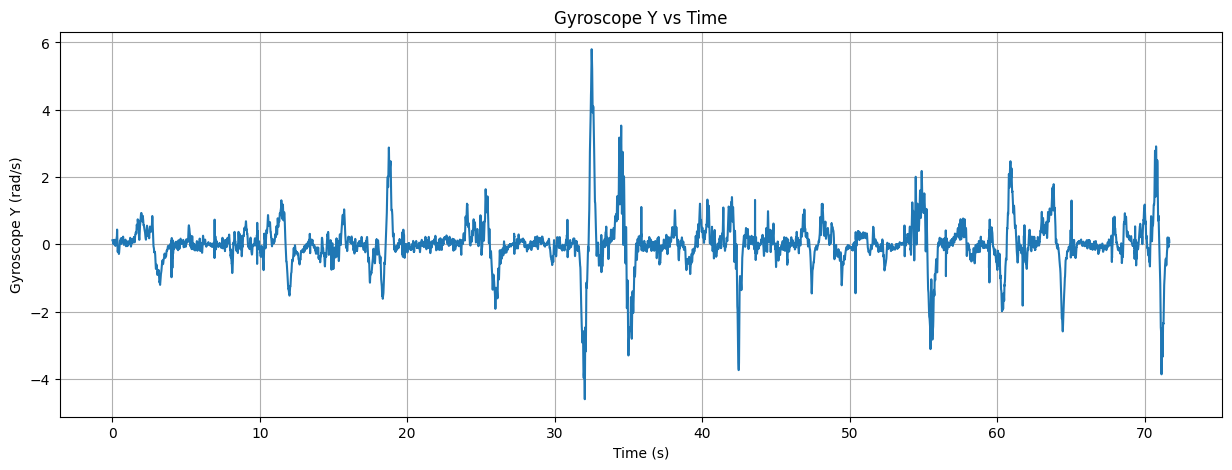

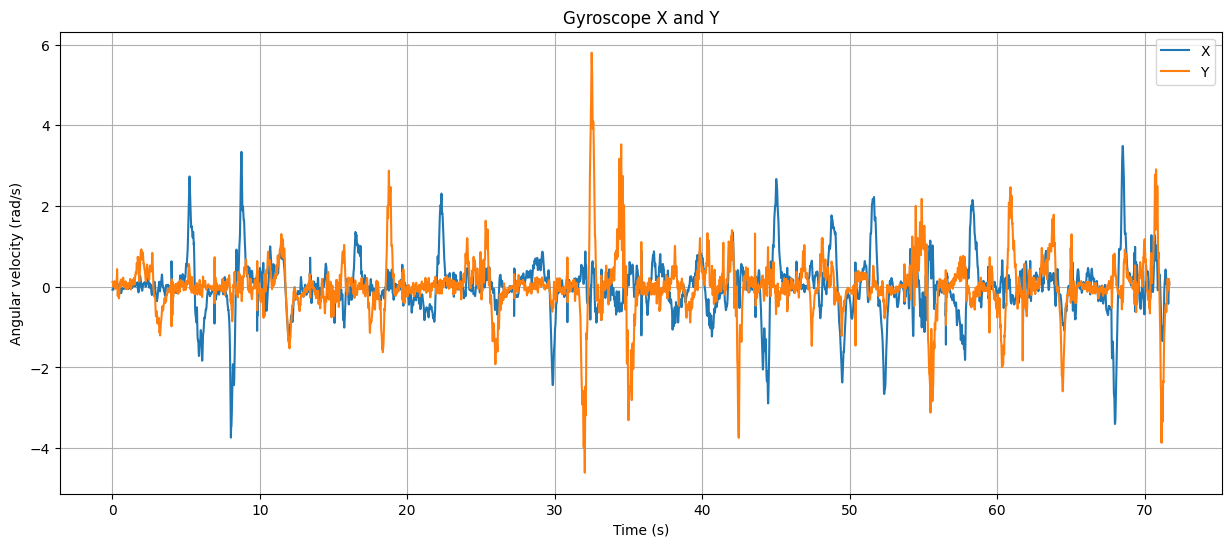

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("/content/Raw Data.csv")

# Display basic information
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nDuration:", df["Time (s)"].iloc[-1], "seconds")

# Plot X
plt.figure(figsize=(15, 5))
plt.plot(df["Time (s)"], df["Gyroscope x (rad/s)"])
plt.xlabel("Time (s)")
plt.ylabel("Gyroscope X (rad/s)")
plt.title("Gyroscope X vs Time")
plt.grid()
plt.show()

# Plot Y
plt.figure(figsize=(15, 5))
plt.plot(df["Time (s)"], df["Gyroscope y (rad/s)"])
plt.xlabel("Time (s)")
plt.ylabel("Gyroscope Y (rad/s)")
plt.title("Gyroscope Y vs Time")
plt.grid()
plt.show()

# Plot X and Y together
plt.figure(figsize=(15, 6))
plt.plot(
    df["Time (s)"],
    df["Gyroscope x (rad/s)"],
    label="X"
)
plt.plot(
    df["Time (s)"],
    df["Gyroscope y (rad/s)"],
    label="Y"
)

plt.xlabel("Time (s)")
plt.ylabel("Angular velocity (rad/s)")
plt.title("Gyroscope X and Y")
plt.legend()
plt.grid()
plt.show()

In [2]:
import pandas as pd
import numpy as np

# =========================
# 1. Load raw data
# =========================

df = pd.read_csv("/content/Raw Data.csv")

# Keep only the columns we need
df = df[
    [
        "Time (s)",
        "Gyroscope x (rad/s)",
        "Gyroscope y (rad/s)"
    ]
].copy()

# Rename for convenience
df.columns = ["time", "gyro_x", "gyro_y"]

print("Raw data shape:", df.shape)
display(df.head())


# =========================
# 2. Window parameters
# =========================

WINDOW_SIZE = 0.5   # seconds
STEP_SIZE = 0.25   # seconds


# =========================
# 3. Create windows
# =========================

windows = []

start_time = df["time"].iloc[0]
end_time = df["time"].iloc[-1]

window_id = 0
start = start_time

while start + WINDOW_SIZE <= end_time:

    end = start + WINDOW_SIZE

    # Get samples inside this window
    window_data = df[
        (df["time"] >= start) &
        (df["time"] < end)
    ]

    # Only keep windows that actually contain data
    if len(window_data) > 0:

        windows.append({
            "window_id": window_id,
            "start_time": start,
            "end_time": end,
            "num_samples": len(window_data)
        })

        window_id += 1

    start += STEP_SIZE


# =========================
# 4. Convert to DataFrame
# =========================

windows_df = pd.DataFrame(windows)

print("\nNumber of windows:", len(windows_df))

display(windows_df.head(10))

Raw data shape: (35846, 3)


,time,gyro_x,gyro_y
0,0.011484,-0.073304,0.118508
1,0.013483,-0.073304,0.118508
2,0.015483,-0.073304,0.118508
3,0.017482,-0.073304,0.118508
4,0.019482,-0.073304,0.118508



Number of windows: 285


,window_id,start_time,end_time,num_samples
0,0,0.011484,0.511484,251
1,1,0.261484,0.761484,250
2,2,0.511484,1.011484,250
3,3,0.761484,1.261484,250
4,4,1.011484,1.511484,250
5,5,1.261484,1.761484,250
6,6,1.511484,2.011484,250
7,7,1.761484,2.261484,250
8,8,2.011484,2.511484,250
9,9,2.261484,2.761484,250


In [3]:
import pandas as pd
import numpy as np

# ==========================================
# Load raw data
# ==========================================

df = pd.read_csv("/content/Raw Data.csv")

df = df[
    [
        "Time (s)",
        "Gyroscope x (rad/s)",
        "Gyroscope y (rad/s)"
    ]
].copy()

df.columns = ["time", "gyro_x", "gyro_y"]


# ==========================================
# Window parameters
# ==========================================

WINDOW_SIZE = 0.5
STEP_SIZE = 0.25

start_time = df["time"].iloc[0]
end_time = df["time"].iloc[-1]


# ==========================================
# Feature extraction function
# ==========================================

def extract_features(window):

    features = {}

    for axis in ["gyro_x", "gyro_y"]:

        signal = window[axis].values

        # Basic statistical features
        features[f"{axis}_mean"] = np.mean(signal)

        features[f"{axis}_variance"] = np.var(signal)

        features[f"{axis}_std"] = np.std(signal)

        features[f"{axis}_min"] = np.min(signal)

        features[f"{axis}_max"] = np.max(signal)

        features[f"{axis}_range"] = np.max(signal) - np.min(signal)

        # RMS
        features[f"{axis}_rms"] = np.sqrt(
            np.mean(signal ** 2)
        )

        # Mean absolute change
        if len(signal) > 1:
            features[f"{axis}_mean_abs_change"] = np.mean(
                np.abs(np.diff(signal))
            )
        else:
            features[f"{axis}_mean_abs_change"] = 0

    return features


# ==========================================
# Create windows + extract features
# ==========================================

feature_rows = []

window_id = 0
start = start_time

while start + WINDOW_SIZE <= end_time:

    end = start + WINDOW_SIZE

    window = df[
        (df["time"] >= start) &
        (df["time"] < end)
    ]

    if len(window) > 0:

        features = extract_features(window)

        row = {
            "window_id": window_id,
            "start_time": start,
            "end_time": end,
            "num_samples": len(window)
        }

        row.update(features)

        feature_rows.append(row)

        window_id += 1

    start += STEP_SIZE


# ==========================================
# Create final feature dataframe
# ==========================================

features_df = pd.DataFrame(feature_rows)

print("Number of windows:", len(features_df))
print("Number of columns:", len(features_df.columns))

display(features_df.head())

Number of windows: 285
Number of columns: 20


,window_id,start_time,end_time,num_samples,gyro_x_mean,gyro_x_variance,gyro_x_std,gyro_x_min,gyro_x_max,gyro_x_range,gyro_x_rms,gyro_x_mean_abs_change,gyro_y_mean,gyro_y_variance,gyro_y_std,gyro_y_min,gyro_y_max,gyro_y_range,gyro_y_rms,gyro_y_mean_abs_change
0,0,0.011484,0.511484,251,-0.012981,0.001018,0.031913,-0.073304,0.055589,0.128893,0.034452,0.002522,0.022726,0.024324,0.155961,-0.288939,0.436158,0.725097,0.157608,0.009635
1,1,0.261484,0.761484,250,-0.036918,0.002425,0.049246,-0.153327,0.055589,0.208916,0.061548,0.002740,0.044845,0.027222,0.164990,-0.288939,0.436158,0.725097,0.170976,0.010767
2,2,0.511484,1.011484,250,-0.039257,0.002387,0.048858,-0.153327,0.040928,0.194255,0.062675,0.002600,0.083197,0.003861,0.062140,-0.059865,0.225409,0.285274,0.103842,0.007208
3,3,0.761484,1.261484,250,-0.012281,0.000751,0.027407,-0.048869,0.040928,0.089797,0.030032,0.002416,0.046516,0.003504,0.059198,-0.067806,0.192423,0.260229,0.075287,0.006526
4,4,1.011484,1.511484,250,-0.005630,0.000814,0.028529,-0.048869,0.049480,0.098349,0.029079,0.002176,0.075325,0.005764,0.075922,-0.070250,0.214414,0.284663,0.106948,0.006295


In [5]:
# ==========================================
# 1. Your recorded fall timestamps
# ==========================================

fall_times = np.array([
    3.00,
    5.75,
    8.27,
    11.89,
    18.71,
    22.14,
    25.94,
    29.89,
    32.51,
    34.96,
    42.31,
    44.76,
    49.25,
    52.09,
    55.33,
    58.10,
    60.65,
    64.13,
    68.37,
    71.19
])


# ==========================================
# 2. Find the closest fall to each window
# ==========================================

def closest_fall_distance(start, end, fall_times):

    # Distance from each fall to the window
    distances = []

    for fall in fall_times:

        if start <= fall <= end:
            # Fall occurs inside the window
            distance = 0

        elif fall < start:
            distance = start - fall

        else:
            distance = fall - end

        distances.append(distance)

    return min(distances)


features_df["distance_to_fall"] = features_df.apply(
    lambda row: closest_fall_distance(
        row["start_time"],
        row["end_time"],
        fall_times
    ),
    axis=1
)


# ==========================================
# 3. Show windows close to falls
# ==========================================

near_falls = features_df[
    features_df["distance_to_fall"] <= 1.0
].copy()

display(
    near_falls[
        [
            "window_id",
            "start_time",
            "end_time",
            "distance_to_fall"
        ]
    ].head(10)
)

,window_id,start_time,end_time,distance_to_fall
6,6,1.511484,2.011484,0.988516
7,7,1.761484,2.261484,0.738516
8,8,2.011484,2.511484,0.488516
9,9,2.261484,2.761484,0.238516
10,10,2.511484,3.011484,0.000000
11,11,2.761484,3.261484,0.000000
12,12,3.011484,3.511484,0.011484
13,13,3.261484,3.761484,0.261484
14,14,3.511484,4.011484,0.511484
15,15,3.761484,4.261484,0.761484


In [6]:
# ==========================================
# Inspect windows around each fall event
# ==========================================

# Show all windows that are within 1 second
# of any recorded fall
near_falls = features_df[
    features_df["distance_to_fall"] <= 1.0
].copy()

# Sort chronologically
near_falls = near_falls.sort_values("start_time")

# Display the relevant columns
display(
    near_falls[
        [
            "window_id",
            "start_time",
            "end_time",
            "distance_to_fall",
            "num_samples"
        ]
    ].reset_index(drop=True)
)

,window_id,start_time,end_time,distance_to_fall,num_samples
0,6,1.511484,2.011484,0.988516,250
1,7,1.761484,2.261484,0.738516,250
2,8,2.011484,2.511484,0.488516,250
3,9,2.261484,2.761484,0.238516,250
4,10,2.511484,3.011484,0.000000,249
...,...,...,...,...,...
190,280,70.011484,70.511484,0.678516,250
191,281,70.261484,70.761484,0.428516,250
192,282,70.511484,71.011484,0.178516,250
193,283,70.761484,71.261484,0.000000,250


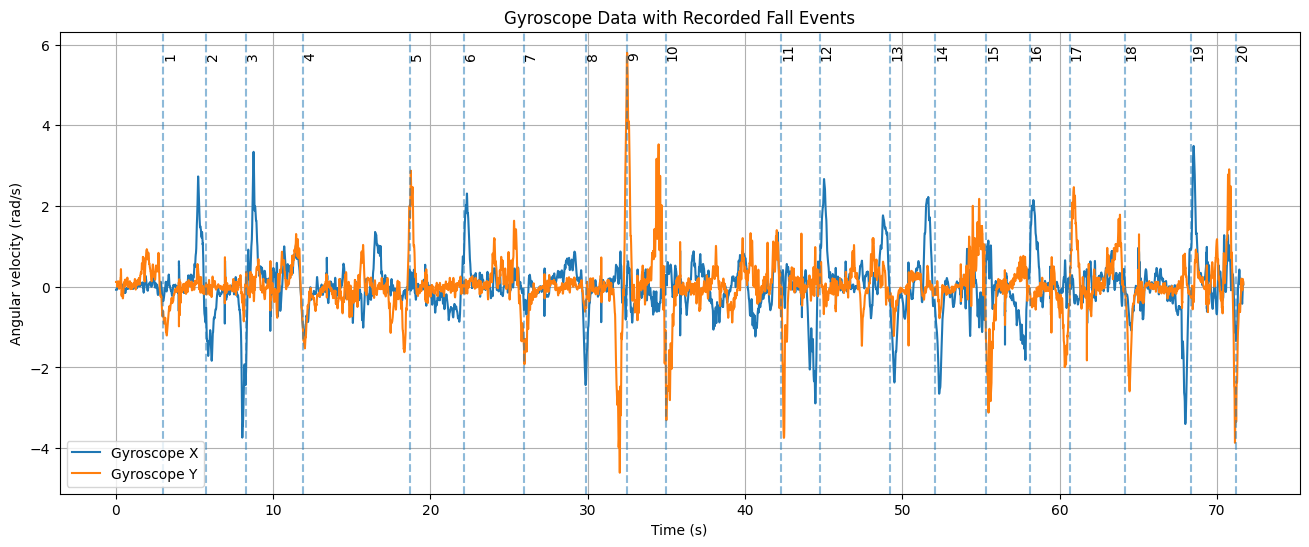

In [7]:
# ==========================================
# Plot gyro data with fall timestamps
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    df["time"],
    df["gyro_x"],
    label="Gyroscope X"
)

plt.plot(
    df["time"],
    df["gyro_y"],
    label="Gyroscope Y"
)

# Add vertical lines for every recorded fall
for i, fall_time in enumerate(fall_times):

    plt.axvline(
        x=fall_time,
        linestyle="--",
        alpha=0.5
    )

    plt.text(
        fall_time,
        plt.ylim()[1] * 0.9,
        str(i + 1),
        rotation=90
    )

plt.xlabel("Time (s)")
plt.ylabel("Angular velocity (rad/s)")
plt.title("Gyroscope Data with Recorded Fall Events")

plt.legend()
plt.grid()

plt.show()

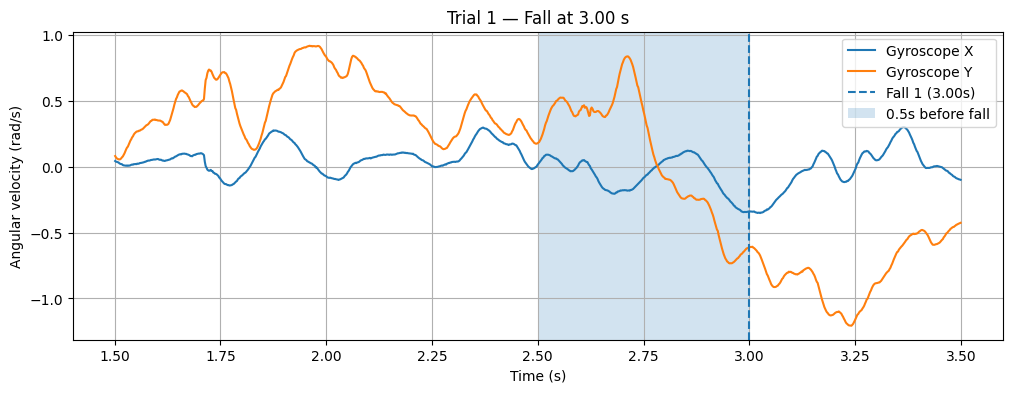

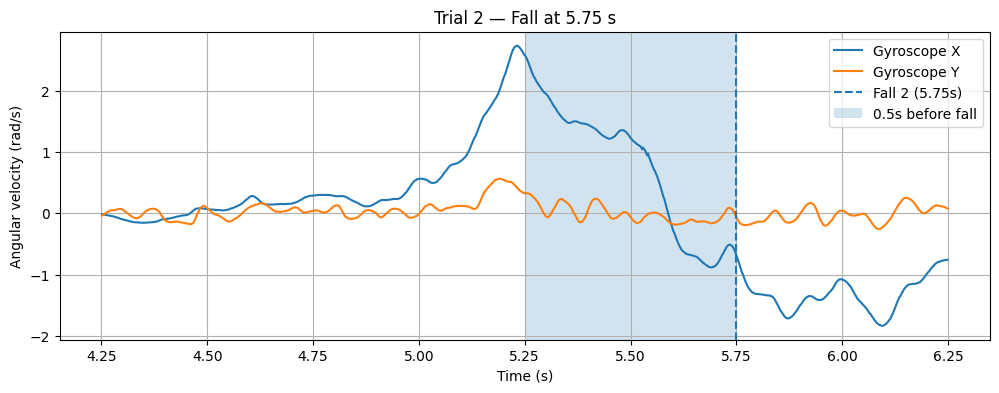

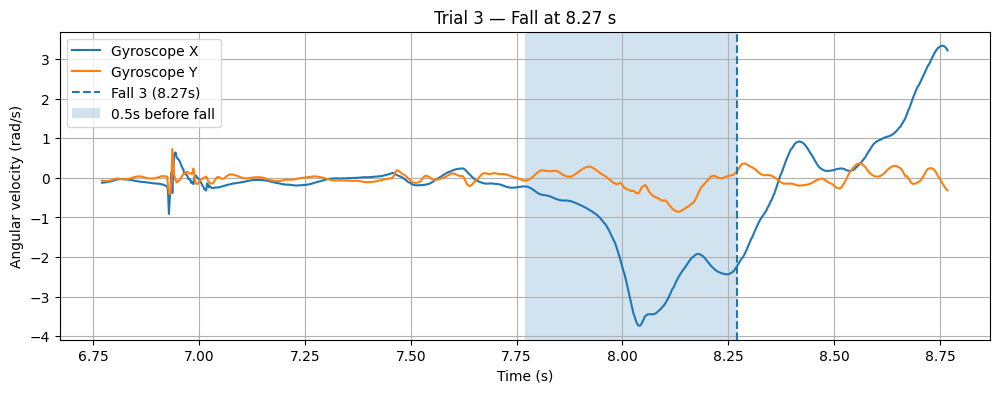

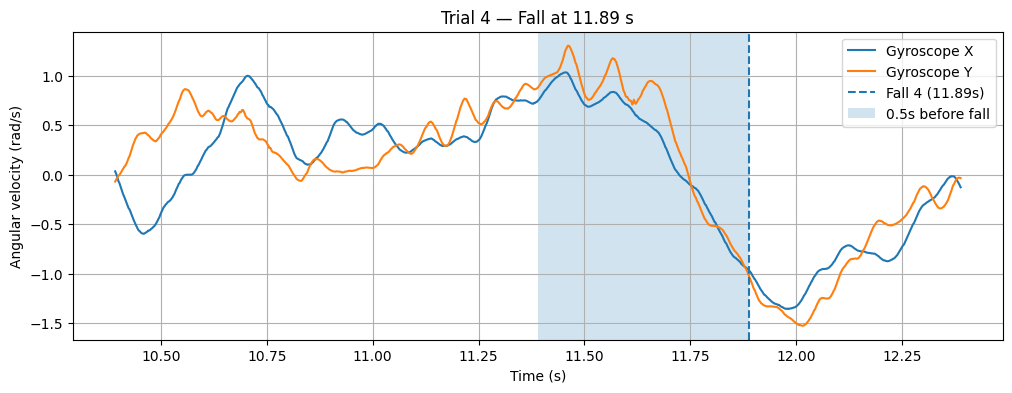

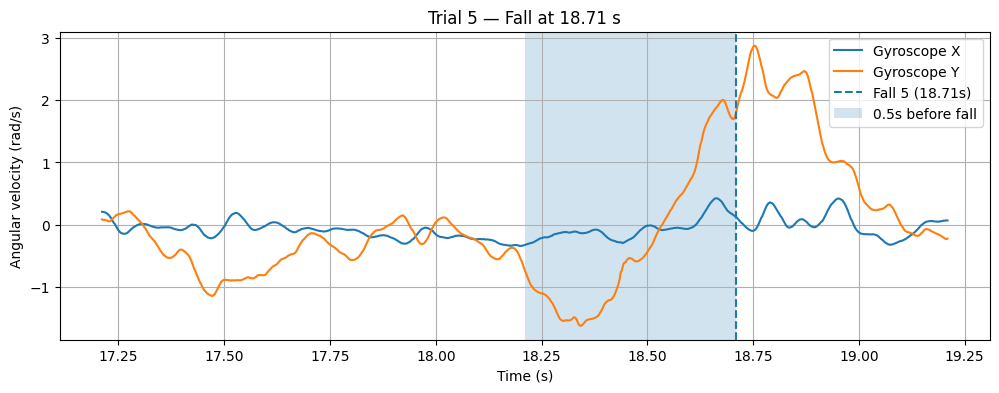

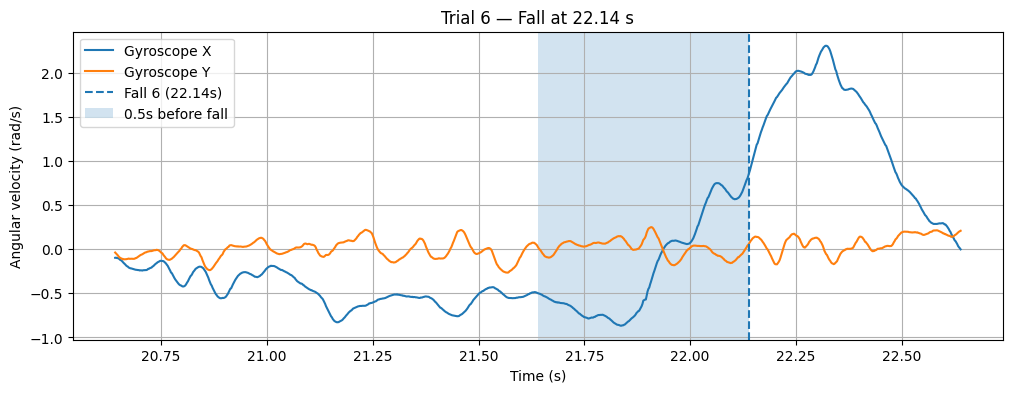

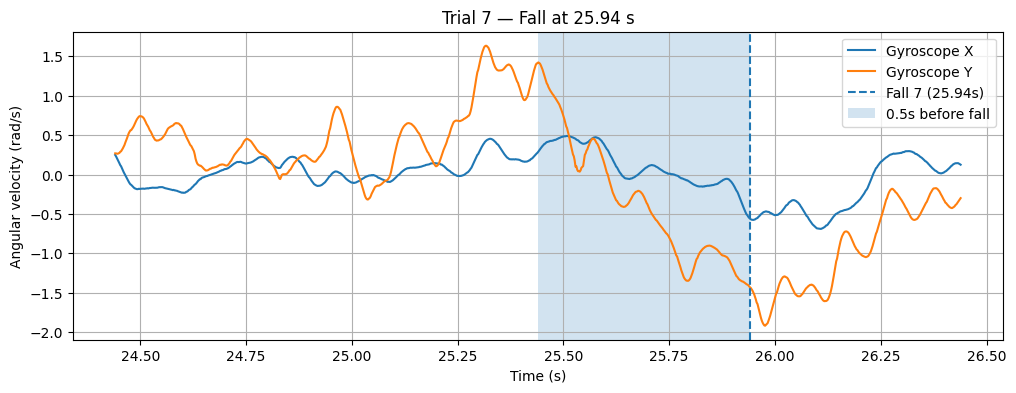

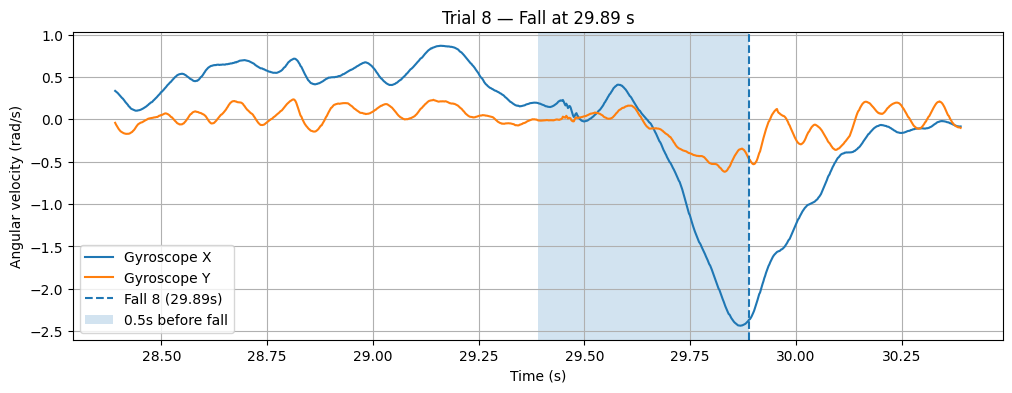

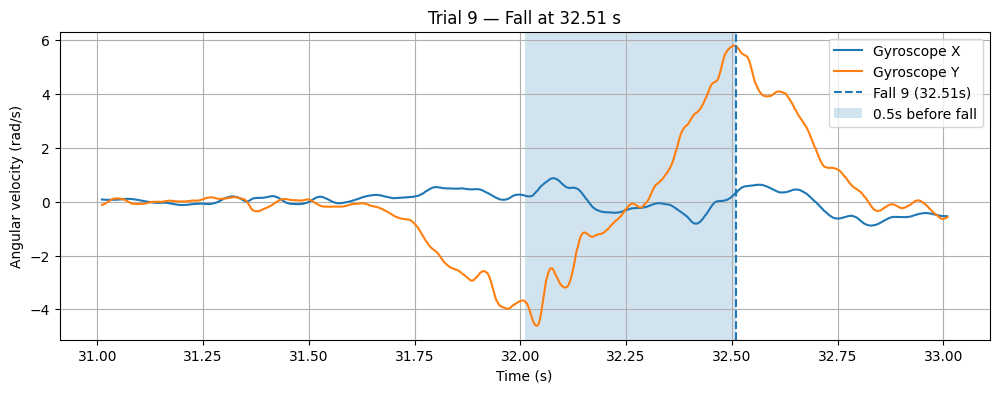

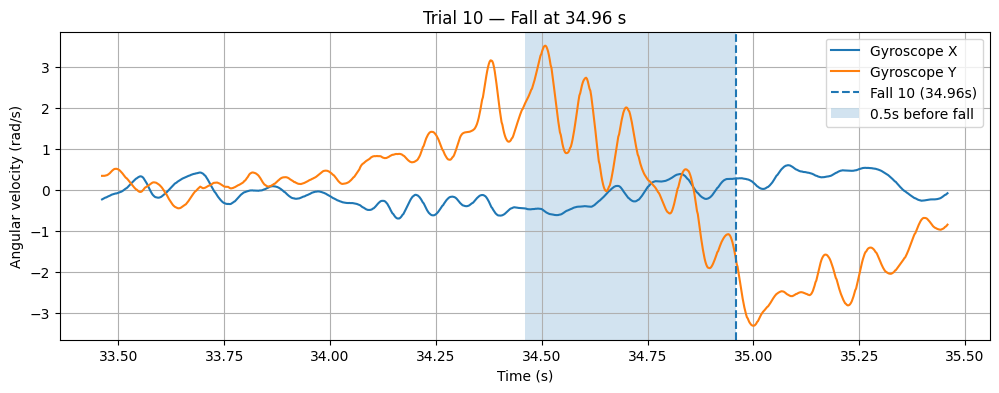

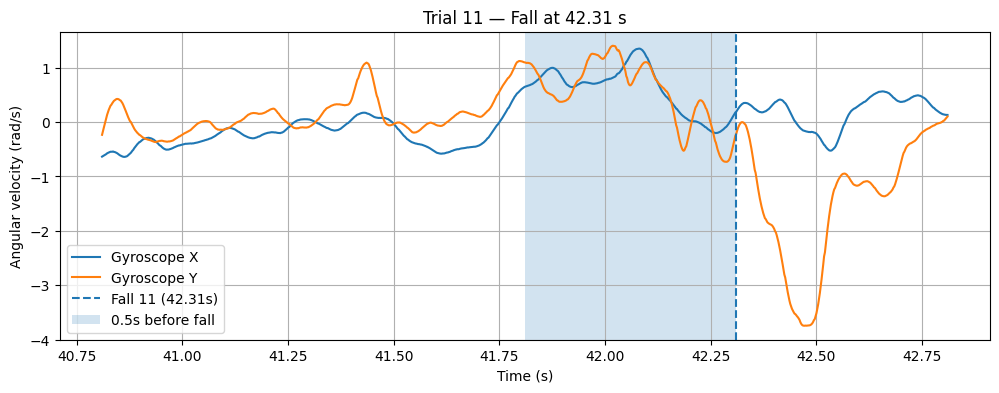

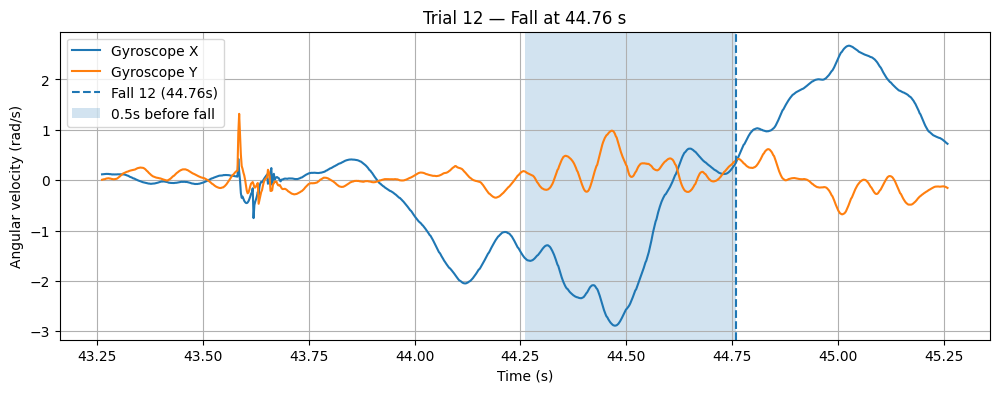

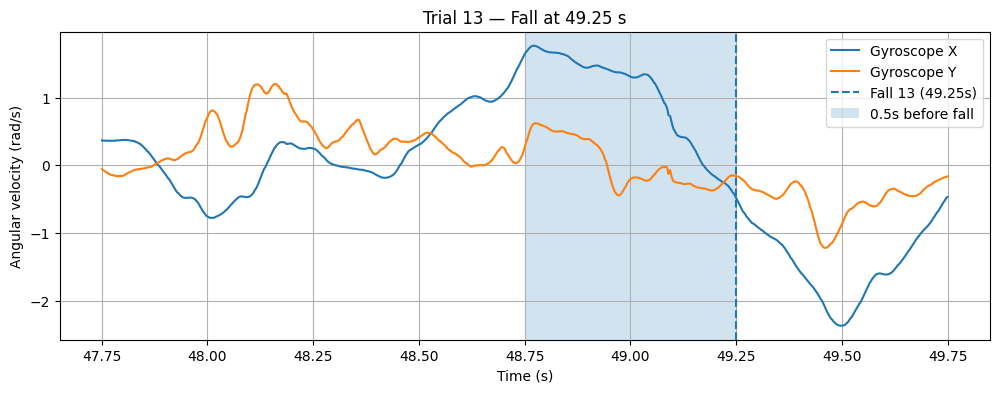

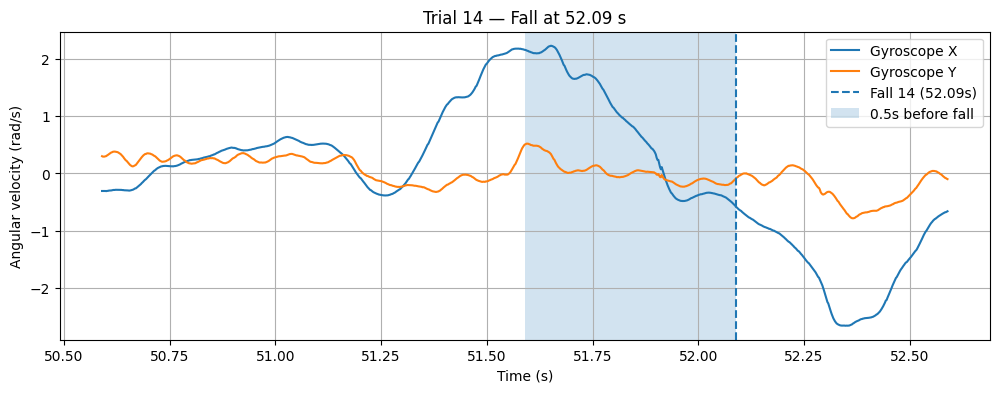

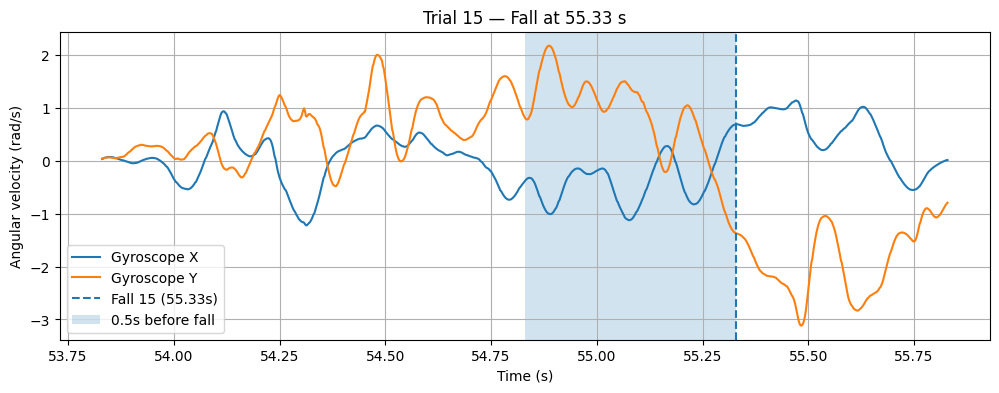

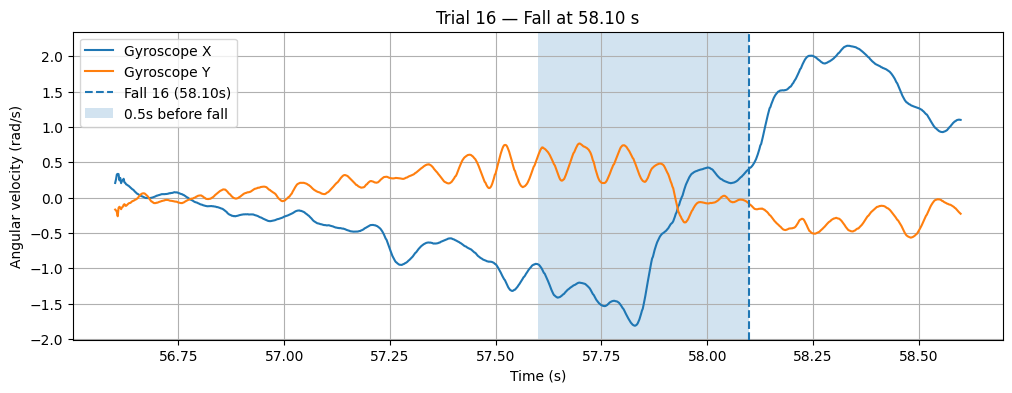

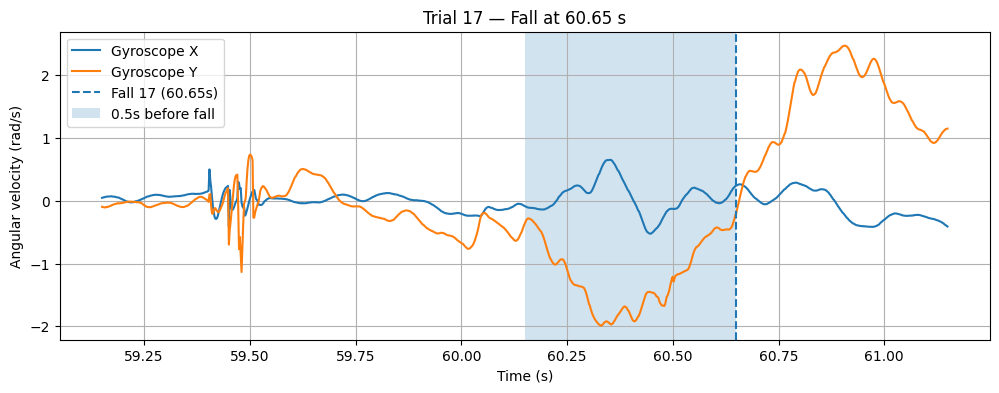

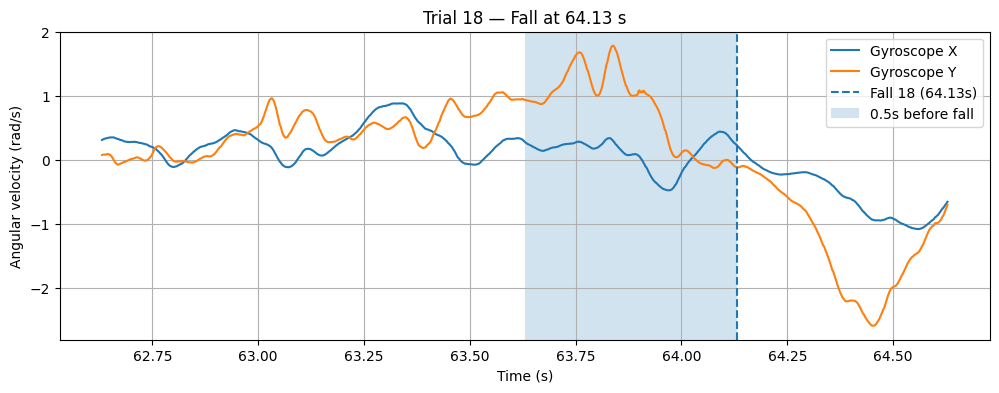

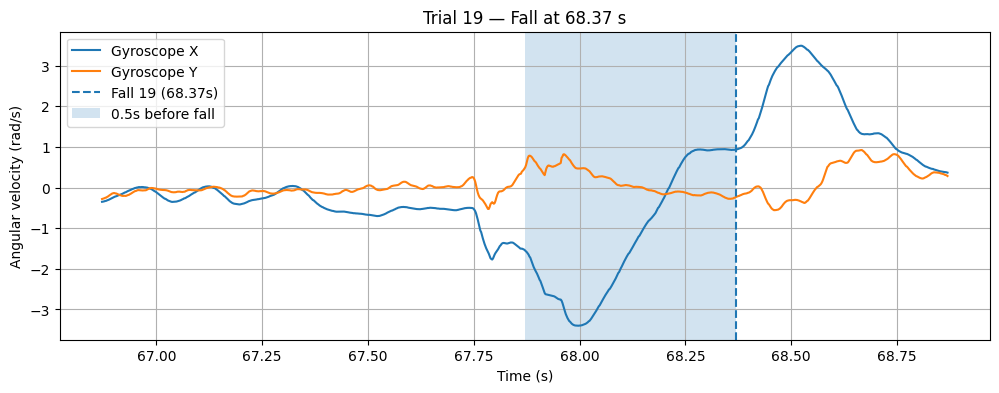

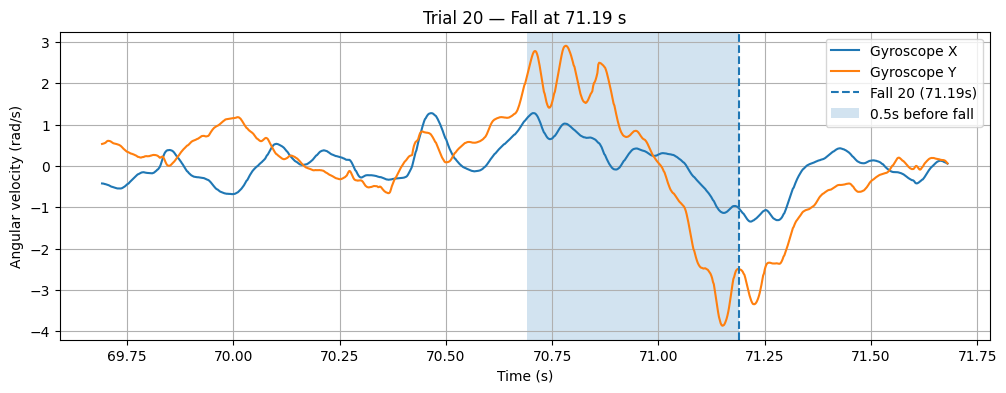

In [8]:
# ==========================================
# Plot a separate graph around each fall
# ==========================================

import matplotlib.pyplot as plt

# How much time to show before and after each fall
BEFORE = 1.5   # seconds
AFTER = 0.5    # seconds

for i, fall_time in enumerate(fall_times):

    start = fall_time - BEFORE
    end = fall_time + AFTER

    # Get data in this region
    segment = df[
        (df["time"] >= start) &
        (df["time"] <= end)
    ]

    plt.figure(figsize=(12, 4))

    plt.plot(
        segment["time"],
        segment["gyro_x"],
        label="Gyroscope X"
    )

    plt.plot(
        segment["time"],
        segment["gyro_y"],
        label="Gyroscope Y"
    )

    # Mark actual fall
    plt.axvline(
        fall_time,
        linestyle="--",
        label=f"Fall {i+1} ({fall_time:.2f}s)"
    )

    # Mark the 0.5-second region immediately before fall
    plt.axvspan(
        fall_time - 0.5,
        fall_time,
        alpha=0.2,
        label="0.5s before fall"
    )

    plt.xlabel("Time (s)")
    plt.ylabel("Angular velocity (rad/s)")
    plt.title(f"Trial {i+1} — Fall at {fall_time:.2f} s")

    plt.legend()
    plt.grid()

    plt.show()

In [9]:
# ==========================================
# Compare feature values around fall events
# ==========================================

# Windows whose center is close to a fall
features_df["window_center"] = (
    features_df["start_time"] + features_df["end_time"]
) / 2

# Distance between window center and nearest fall
features_df["center_distance_to_fall"] = features_df[
    "window_center"
].apply(
    lambda x: np.min(np.abs(fall_times - x))
)

# Show windows within 1 second of a fall
fall_related = features_df[
    features_df["center_distance_to_fall"] <= 1.0
].copy()

fall_related = fall_related.sort_values(
    "window_center"
)

display(
    fall_related[
        [
            "window_id",
            "start_time",
            "end_time",
            "window_center",
            "center_distance_to_fall",
            "gyro_x_mean",
            "gyro_x_std",
            "gyro_x_rms",
            "gyro_y_mean",
            "gyro_y_std",
            "gyro_y_rms"
        ]
    ].reset_index(drop=True)
)

,window_id,start_time,end_time,window_center,center_distance_to_fall,gyro_x_mean,gyro_x_std,gyro_x_rms,gyro_y_mean,gyro_y_std,gyro_y_rms
0,7,1.761484,2.261484,2.011484,0.988516,0.055718,0.107633,0.121200,0.572686,0.237168,0.619853
1,8,2.011484,2.511484,2.261484,0.738516,0.082665,0.093075,0.124484,0.426179,0.196263,0.469199
2,9,2.261484,2.761484,2.511484,0.488516,0.030040,0.136348,0.139618,0.405263,0.163065,0.436839
3,10,2.511484,3.011484,2.761484,0.238516,-0.066094,0.136764,0.151897,0.083402,0.470028,0.477370
4,11,2.761484,3.261484,3.011484,0.011484,-0.085533,0.156786,0.178599,-0.633018,0.367192,0.731807
...,...,...,...,...,...,...,...,...,...,...,...
152,280,70.011484,70.511484,70.261484,0.928516,0.166163,0.441676,0.471898,0.116722,0.466010,0.480405
153,281,70.261484,70.761484,70.511484,0.678516,0.336604,0.535639,0.632623,0.620561,0.870949,1.069415
154,282,70.511484,71.011484,70.761484,0.428516,0.475656,0.393983,0.617634,1.355886,0.800154,1.574381
155,283,70.761484,71.261484,71.011484,0.178516,-0.096160,0.720047,0.726440,-0.428600,2.114182,2.157189


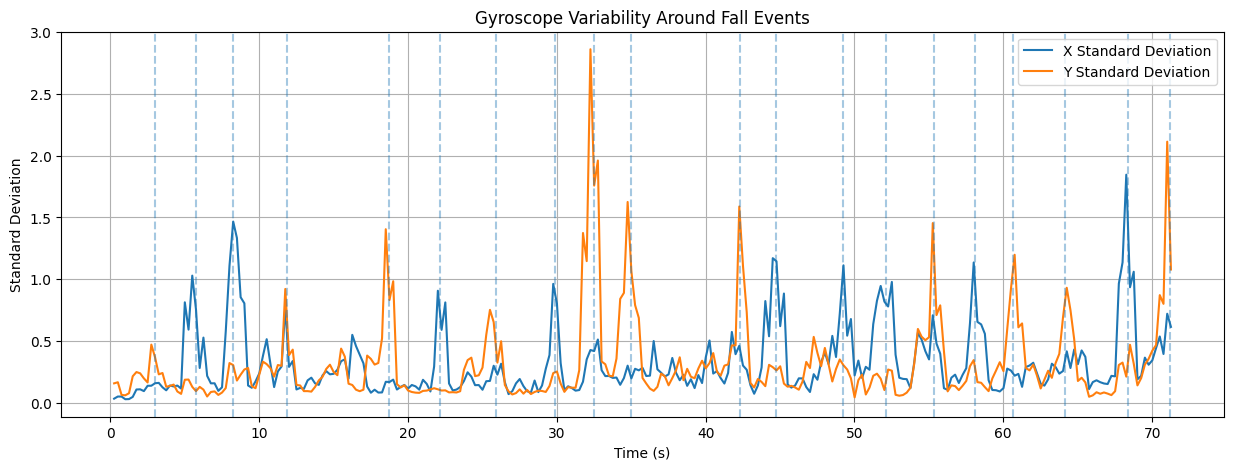

In [10]:
# ==========================================
# Plot feature values against time
# ==========================================

plt.figure(figsize=(15, 5))

plt.plot(
    features_df["window_center"],
    features_df["gyro_x_std"],
    label="X Standard Deviation"
)

plt.plot(
    features_df["window_center"],
    features_df["gyro_y_std"],
    label="Y Standard Deviation"
)

# Mark fall events
for fall_time in fall_times:
    plt.axvline(
        fall_time,
        linestyle="--",
        alpha=0.4
    )

plt.xlabel("Time (s)")
plt.ylabel("Standard Deviation")
plt.title("Gyroscope Variability Around Fall Events")

plt.legend()
plt.grid()

plt.show()

In [11]:
# ==========================================
# CREATE INITIAL SAFE / UNSAFE LABELS
# ==========================================

# Copy our feature dataframe
labeled_df = features_df.copy()

# Your recorded fall times
fall_times = np.array([
    3.00,
    5.75,
    8.27,
    11.89,
    18.71,
    22.14,
    25.94,
    29.89,
    32.51,
    34.96,
    42.31,
    44.76,
    49.25,
    52.09,
    55.33,
    58.10,
    60.65,
    64.13,
    68.37,
    71.19
])

# ------------------------------------------
# Initial definition:
#
# 1 = window immediately preceding a fall
# 0 = safe
#
# We use the window's END time.
# ------------------------------------------

labeled_df["label"] = 0

UNSAFE_DURATION = 0.5  # seconds

for fall_time in fall_times:

    unsafe_start = fall_time - UNSAFE_DURATION
    unsafe_end = fall_time

    # Label windows whose time interval overlaps
    # the pre-fall period
    mask = (
        (labeled_df["start_time"] < unsafe_end) &
        (labeled_df["end_time"] > unsafe_start) &
        (labeled_df["end_time"] <= unsafe_end + 0.001)
    )

    labeled_df.loc[mask, "label"] = 1


# ==========================================
# Remove windows AFTER a fall
# ==========================================

# We don't want post-fall data to become
# misleading SAFE examples immediately after
# an event.

POST_FALL_EXCLUSION = 0.5

exclude_mask = np.zeros(len(labeled_df), dtype=bool)

for fall_time in fall_times:

    post_start = fall_time
    post_end = fall_time + POST_FALL_EXCLUSION

    exclude_mask |= (
        (labeled_df["start_time"] < post_end) &
        (labeled_df["end_time"] > post_start)
    )

# Mark these as unknown instead of SAFE
labeled_df.loc[exclude_mask, "label"] = -1


# ==========================================
# Inspect label distribution
# ==========================================

print("Initial label counts:")
print(labeled_df["label"].value_counts())

print("\n0 = SAFE")
print("1 = UNSAFE")
print("-1 = EXCLUDED / ambiguous")


# Show examples
display(
    labeled_df[
        [
            "window_id",
            "start_time",
            "end_time",
            "label"
        ]
    ].head(30)
)

Initial label counts:
label
 0    167
-1     78
 1     40
Name: count, dtype: int64

0 = SAFE
1 = UNSAFE
-1 = EXCLUDED / ambiguous


,window_id,start_time,end_time,label
0,0,0.011484,0.511484,0
1,1,0.261484,0.761484,0
2,2,0.511484,1.011484,0
3,3,0.761484,1.261484,0
4,4,1.011484,1.511484,0
5,5,1.261484,1.761484,0
6,6,1.511484,2.011484,0
7,7,1.761484,2.261484,0
8,8,2.011484,2.511484,1
9,9,2.261484,2.761484,1


In [12]:
# Check how many windows have each label

print("Label counts:")
print(labeled_df["label"].value_counts().sort_index())

print("\nLabel percentages:")
print(
    (labeled_df["label"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Label counts:
label
-1     78
 0    167
 1     40
Name: count, dtype: int64

Label percentages:
label
-1    27.37
 0    58.60
 1    14.04
Name: proportion, dtype: float64


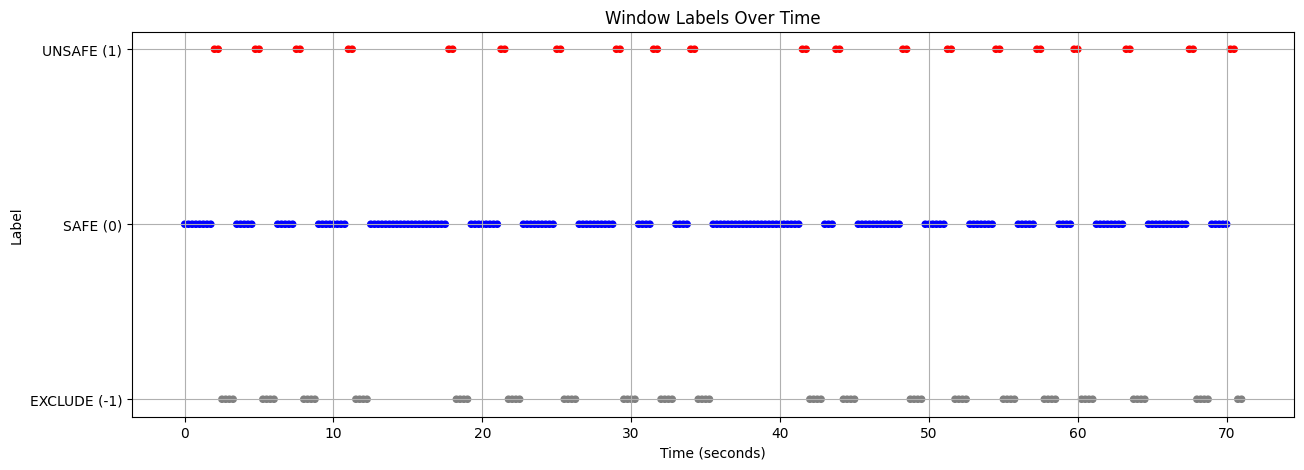

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

colors = labeled_df["label"].map({
    -1: "gray",
    0: "blue",
    1: "red"
})

plt.scatter(
    labeled_df["start_time"],
    labeled_df["label"],
    c=colors,
    s=20
)

plt.yticks(
    [-1, 0, 1],
    ["EXCLUDE (-1)", "SAFE (0)", "UNSAFE (1)"]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Label")
plt.title("Window Labels Over Time")
plt.grid(True)
plt.show()

In [14]:
# ============================================
# CREATE FINAL ML DATASET
# ============================================

# Remove excluded windows (-1)
final_dataset = labeled_df[labeled_df["label"] != -1].copy()

# Feature columns
feature_columns = [
    "gyro_x_mean",
    "gyro_x_variance",
    "gyro_x_std",
    "gyro_x_min",
    "gyro_x_max",
    "gyro_x_range",
    "gyro_x_rms",
    "gyro_x_mean_abs_change",

    "gyro_y_mean",
    "gyro_y_variance",
    "gyro_y_std",
    "gyro_y_min",
    "gyro_y_max",
    "gyro_y_range",
    "gyro_y_rms",
    "gyro_y_mean_abs_change"
]

# Final columns = features + label
final_columns = feature_columns + ["label"]

final_dataset = final_dataset[final_columns]

# Reset row numbers
final_dataset.reset_index(drop=True, inplace=True)

# Save
final_dataset.to_csv("final_dataset.csv", index=False)

# Display information
print("FINAL DATASET CREATED")
print("---------------------")

print("Shape:", final_dataset.shape)

print("\nLabel counts:")
print(final_dataset["label"].value_counts().sort_index())

print("\nFirst 10 rows:")
display(final_dataset.head(10))

FINAL DATASET CREATED
---------------------
Shape: (207, 17)

Label counts:
label
0    167
1     40
Name: count, dtype: int64

First 10 rows:


,gyro_x_mean,gyro_x_variance,gyro_x_std,gyro_x_min,gyro_x_max,gyro_x_range,gyro_x_rms,gyro_x_mean_abs_change,gyro_y_mean,gyro_y_variance,gyro_y_std,gyro_y_min,gyro_y_max,gyro_y_range,gyro_y_rms,gyro_y_mean_abs_change,label
0,-0.012981,0.001018,0.031913,-0.073304,0.055589,0.128893,0.034452,0.002522,0.022726,0.024324,0.155961,-0.288939,0.436158,0.725097,0.157608,0.009635,0
1,-0.036918,0.002425,0.049246,-0.153327,0.055589,0.208916,0.061548,0.002740,0.044845,0.027222,0.164990,-0.288939,0.436158,0.725097,0.170976,0.010767,0
2,-0.039257,0.002387,0.048858,-0.153327,0.040928,0.194255,0.062675,0.002600,0.083197,0.003861,0.062140,-0.059865,0.225409,0.285274,0.103842,0.007208,0
3,-0.012281,0.000751,0.027407,-0.048869,0.040928,0.089797,0.030032,0.002416,0.046516,0.003504,0.059198,-0.067806,0.192423,0.260229,0.075287,0.006526,0
4,-0.005630,0.000814,0.028529,-0.048869,0.049480,0.098349,0.029079,0.002176,0.075325,0.005764,0.075922,-0.070250,0.214414,0.284663,0.106948,0.006295,0
5,0.021840,0.002132,0.046178,-0.130725,0.103847,0.234572,0.051082,0.002912,0.268595,0.045526,0.213368,-0.070250,0.740369,0.810618,0.343029,0.007823,0
6,0.052341,0.011264,0.106130,-0.141721,0.277333,0.419054,0.118335,0.005073,0.516694,0.061297,0.247583,0.058032,0.921185,0.863153,0.572949,0.010799,0
7,0.055718,0.011585,0.107633,-0.141721,0.277333,0.419054,0.121200,0.004784,0.572686,0.056249,0.237168,0.129503,0.921185,0.791681,0.619853,0.010039,0
8,0.082665,0.008663,0.093075,-0.099571,0.298713,0.398284,0.124484,0.004497,0.426179,0.038519,0.196263,0.134390,0.844827,0.710436,0.469199,0.008506,1
9,0.030040,0.018591,0.136348,-0.204640,0.298713,0.503353,0.139618,0.005635,0.405263,0.026590,0.163065,0.134390,0.839940,0.705549,0.436839,0.011781,1


In [15]:
# ============================================
# CLEAN, SUMMARIZE AND SAVE FINAL DATASET
# ============================================

# 1. Rename feature columns
rename_columns = {
    "gyro_x_mean": "x_mean",
    "gyro_x_variance": "x_variance",
    "gyro_x_std": "x_std",
    "gyro_x_min": "x_min",
    "gyro_x_max": "x_max",
    "gyro_x_range": "x_range",
    "gyro_x_rms": "x_rms",
    "gyro_x_mean_abs_change": "x_mean_abs_change",

    "gyro_y_mean": "y_mean",
    "gyro_y_variance": "y_variance",
    "gyro_y_std": "y_std",
    "gyro_y_min": "y_min",
    "gyro_y_max": "y_max",
    "gyro_y_range": "y_range",
    "gyro_y_rms": "y_rms",
    "gyro_y_mean_abs_change": "y_mean_abs_change"
}

final_dataset = final_dataset.rename(columns=rename_columns)


# 2. Reset index
final_dataset.reset_index(drop=True, inplace=True)


# ============================================
# 3. DATASET SUMMARY
# ============================================

print("=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)

# Shape
print(f"\nNumber of samples : {final_dataset.shape[0]}")
print(f"Number of features: {final_dataset.shape[1] - 1}")
print(f"Total columns     : {final_dataset.shape[1]}")

# Window information
print("\nWindow configuration:")
print("Window size       : 0.5 seconds")
print("Window overlap    : 50%")
print("Step size         : 0.25 seconds")

# Features
print("\nFeature columns:")
for i, column in enumerate(final_dataset.columns[:-1], start=1):
    print(f"{i:2}. {column}")

# Labels
print("\nLabel distribution:")
print(final_dataset["label"].value_counts().sort_index())

print("\nLabel percentages:")
label_percentages = (
    final_dataset["label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

for label, percentage in label_percentages.items():
    label_name = "SAFE" if label == 0 else "UNSAFE"
    print(f"{label} = {label_name:<6}: {percentage:.2f}%")

# Missing values
print("\nMissing values:")
print(final_dataset.isnull().sum().sum())

# Duplicate rows
print("\nDuplicate rows:")
print(final_dataset.duplicated().sum())

# Data types
print("\nData types:")
print(final_dataset.dtypes)

# Statistical summary
print("\nStatistical summary:")
display(final_dataset.describe())


# ============================================
# 4. DISPLAY FIRST FEW ROWS
# ============================================

print("\nFirst 10 rows:")
display(final_dataset.head(10))


# ============================================
# 5. SAVE FINAL DATASET
# ============================================

final_dataset.to_csv("final_dataset.csv", index=False)

print("\n" + "=" * 60)
print("FINAL DATASET SAVED")
print("=" * 60)
print("Filename: final_dataset.csv")

FINAL DATASET SUMMARY

Number of samples : 207
Number of features: 16
Total columns     : 17

Window configuration:
Window size       : 0.5 seconds
Window overlap    : 50%
Step size         : 0.25 seconds

Feature columns:
 1. x_mean
 2. x_variance
 3. x_std
 4. x_min
 5. x_max
 6. x_range
 7. x_rms
 8. x_mean_abs_change
 9. y_mean
10. y_variance
11. y_std
12. y_min
13. y_max
14. y_range
15. y_rms
16. y_mean_abs_change

Label distribution:
label
0    167
1     40
Name: count, dtype: int64

Label percentages:
0 = SAFE  : 80.68%
1 = UNSAFE: 19.32%

Missing values:
0

Duplicate rows:
0

Data types:
x_mean               float64
x_variance           float64
x_std                float64
x_min                float64
x_max                float64
x_range              float64
x_rms                float64
x_mean_abs_change    float64
y_mean               float64
y_variance           float64
y_std                float64
y_min                float64
y_max                float64
y_range             

,x_mean,x_variance,x_std,x_min,x_max,x_range,x_rms,x_mean_abs_change,y_mean,y_variance,y_std,y_min,y_max,y_range,y_rms,y_mean_abs_change,label
count,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean,-0.002451,0.094744,0.247140,-0.534371,0.476292,1.010663,0.386862,0.012049,0.079181,0.088473,0.232885,-0.431070,0.602838,1.033909,0.346481,0.015077,0.193237
std,0.417197,0.177692,0.183928,0.591083,0.495467,0.631112,0.344782,0.007481,0.390512,0.193447,0.185483,0.544978,0.595367,0.695264,0.356470,0.009373,0.395794
min,-1.791397,0.000751,0.027407,-3.737273,-0.844216,0.089797,0.029079,0.002176,-2.436082,0.001794,0.042356,-4.607146,-0.193033,0.200975,0.049630,0.003592,0.000000
25%,-0.129354,0.017421,0.131990,-0.782518,0.193033,0.572381,0.178411,0.006742,-0.053023,0.010932,0.104558,-0.551000,0.205862,0.520457,0.120177,0.008595,0.000000
50%,-0.000108,0.039378,0.198440,-0.408669,0.425773,0.894307,0.294289,0.009237,0.009402,0.037606,0.193922,-0.290161,0.430049,0.881479,0.228793,0.012379,0.000000
75%,0.159993,0.088113,0.296817,-0.151800,0.648433,1.270294,0.468834,0.015009,0.209370,0.092852,0.304716,-0.161574,0.852462,1.327716,0.445800,0.018527,0.000000
max,1.499342,1.290744,1.136109,0.492968,2.733011,4.252844,2.099806,0.043391,1.644009,1.888429,1.374201,0.185703,3.527136,4.523457,2.692307,0.073083,1.000000



First 10 rows:


,x_mean,x_variance,x_std,x_min,x_max,x_range,x_rms,x_mean_abs_change,y_mean,y_variance,y_std,y_min,y_max,y_range,y_rms,y_mean_abs_change,label
0,-0.012981,0.001018,0.031913,-0.073304,0.055589,0.128893,0.034452,0.002522,0.022726,0.024324,0.155961,-0.288939,0.436158,0.725097,0.157608,0.009635,0
1,-0.036918,0.002425,0.049246,-0.153327,0.055589,0.208916,0.061548,0.002740,0.044845,0.027222,0.164990,-0.288939,0.436158,0.725097,0.170976,0.010767,0
2,-0.039257,0.002387,0.048858,-0.153327,0.040928,0.194255,0.062675,0.002600,0.083197,0.003861,0.062140,-0.059865,0.225409,0.285274,0.103842,0.007208,0
3,-0.012281,0.000751,0.027407,-0.048869,0.040928,0.089797,0.030032,0.002416,0.046516,0.003504,0.059198,-0.067806,0.192423,0.260229,0.075287,0.006526,0
4,-0.005630,0.000814,0.028529,-0.048869,0.049480,0.098349,0.029079,0.002176,0.075325,0.005764,0.075922,-0.070250,0.214414,0.284663,0.106948,0.006295,0
5,0.021840,0.002132,0.046178,-0.130725,0.103847,0.234572,0.051082,0.002912,0.268595,0.045526,0.213368,-0.070250,0.740369,0.810618,0.343029,0.007823,0
6,0.052341,0.011264,0.106130,-0.141721,0.277333,0.419054,0.118335,0.005073,0.516694,0.061297,0.247583,0.058032,0.921185,0.863153,0.572949,0.010799,0
7,0.055718,0.011585,0.107633,-0.141721,0.277333,0.419054,0.121200,0.004784,0.572686,0.056249,0.237168,0.129503,0.921185,0.791681,0.619853,0.010039,0
8,0.082665,0.008663,0.093075,-0.099571,0.298713,0.398284,0.124484,0.004497,0.426179,0.038519,0.196263,0.134390,0.844827,0.710436,0.469199,0.008506,1
9,0.030040,0.018591,0.136348,-0.204640,0.298713,0.503353,0.139618,0.005635,0.405263,0.026590,0.163065,0.134390,0.839940,0.705549,0.436839,0.011781,1



FINAL DATASET SAVED
Filename: final_dataset.csv


In [16]:
# ============================================
# STEP 1: PREPARE FEATURES (X) AND LABEL (y)
# ============================================

# Separate input features and target
X = final_dataset.drop("label", axis=1)
y = final_dataset["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(list(X.columns))

print("\nLabel distribution:")
print(y.value_counts().sort_index())

print("\nLabels:")
print("0 = SAFE")
print("1 = UNSAFE")

X shape: (207, 16)
y shape: (207,)

Feature columns:
['x_mean', 'x_variance', 'x_std', 'x_min', 'x_max', 'x_range', 'x_rms', 'x_mean_abs_change', 'y_mean', 'y_variance', 'y_std', 'y_min', 'y_max', 'y_range', 'y_rms', 'y_mean_abs_change']

Label distribution:
label
0    167
1     40
Name: count, dtype: int64

Labels:
0 = SAFE
1 = UNSAFE


In [17]:
# ============================================
# STEP 2: TRAIN / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())

Training set:
X_train: (165, 16)
y_train: (165,)

Testing set:
X_test: (42, 16)
y_test: (42,)

Training label distribution:
label
0    133
1     32
Name: count, dtype: int64

Testing label distribution:
label
0    34
1     8
Name: count, dtype: int64


In [18]:
# ============================================
# STEP 3: FEATURE SCALING
# ============================================

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape  :", X_train_scaled.shape)

print("\nOriginal testing shape :", X_test.shape)
print("Scaled testing shape   :", X_test_scaled.shape)

print("\nFirst 5 scaled training samples:")
print(X_train_scaled[:5])

Original training shape: (165, 16)
Scaled training shape  : (165, 16)

Original testing shape : (42, 16)
Scaled testing shape   : (42, 16)

First 5 scaled training samples:
[[-0.45218991 -0.53062544 -0.76183047  0.07966808 -0.78280505 -0.73021089
  -0.58358763  0.30021184 -0.37645568 -0.39040026 -0.72456636  0.0722811
  -0.50791487 -0.47736572 -0.61913578 -0.01441233]
 [-0.10391803 -0.05637597  0.22790259 -0.07124396  0.33649662  0.34864921
  -0.28157559  0.14669022 -2.95642802  1.32966525  1.96789973 -2.60380737
  -1.35520258  1.15028338  2.54440056  0.79845974]
 [-0.11269648 -0.62136901 -1.26694966  0.77068622 -0.90377623 -1.48072227
  -1.05926994 -1.34401494 -0.11086965 -0.31604213 -0.40753003  0.26821821
  -0.22767497 -0.41837348 -0.53831663 -0.57514849]
 [-0.33614223 -0.44451422 -0.50301734 -0.78722499  0.31484921  1.00321458
  -0.5758342   1.84740993 -0.19249562 -0.39693137 -0.76205837  0.06403111
   0.30105884  0.19031902 -0.72299559  0.52740495]
 [-0.17183314  0.45391198  0.862

In [19]:
# ============================================
# STEP 4: LOGISTIC REGRESSION BASELINE
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create the model
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Train
logistic_model.fit(X_train_scaled, y_train)

# Predict
y_pred_lr = logistic_model.predict(X_test_scaled)

# ============================================
# EVALUATION
# ============================================

accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, zero_division=0)
recall = recall_score(y_test, y_pred_lr, zero_division=0)
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print("=" * 50)
print("LOGISTIC REGRESSION RESULTS")
print("=" * 50)

print(f"\nAccuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["SAFE", "UNSAFE"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS

Accuracy : 0.8810
Precision: 0.7143
Recall   : 0.6250
F1 Score : 0.6667

Classification Report:
              precision    recall  f1-score   support

        SAFE       0.91      0.94      0.93        34
      UNSAFE       0.71      0.62      0.67         8

    accuracy                           0.88        42
   macro avg       0.81      0.78      0.80        42
weighted avg       0.88      0.88      0.88        42

Confusion Matrix:
[[32  2]
 [ 3  5]]


In [20]:
# ============================================
# STEP 5: DECISION TREE
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create the Decision Tree
tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict on test data
y_pred_tree = tree_model.predict(X_test)

# ============================================
# EVALUATION
# ============================================

accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree, zero_division=0)
recall_tree = recall_score(y_test, y_pred_tree, zero_division=0)
f1_tree = f1_score(y_test, y_pred_tree, zero_division=0)

print("=" * 50)
print("DECISION TREE RESULTS")
print("=" * 50)

print(f"\nAccuracy : {accuracy_tree:.4f}")
print(f"Precision: {precision_tree:.4f}")
print(f"Recall   : {recall_tree:.4f}")
print(f"F1 Score : {f1_tree:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=["SAFE", "UNSAFE"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

DECISION TREE RESULTS

Accuracy : 0.9286
Precision: 1.0000
Recall   : 0.6250
F1 Score : 0.7692

Classification Report:
              precision    recall  f1-score   support

        SAFE       0.92      1.00      0.96        34
      UNSAFE       1.00      0.62      0.77         8

    accuracy                           0.93        42
   macro avg       0.96      0.81      0.86        42
weighted avg       0.93      0.93      0.92        42

Confusion Matrix:
[[34  0]
 [ 3  5]]


In [21]:
# ============================================
# STEP 6: SMALL MLP NEURAL NETWORK
# ============================================

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create a small neural network
mlp_model = MLPClassifier(
    hidden_layer_sizes=(8, 4),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

# Train
mlp_model.fit(X_train_scaled, y_train)

# Predict
y_pred_mlp = mlp_model.predict(X_test_scaled)

# ============================================
# EVALUATION
# ============================================

accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
precision_mlp = precision_score(y_test, y_pred_mlp, zero_division=0)
recall_mlp = recall_score(y_test, y_pred_mlp, zero_division=0)
f1_mlp = f1_score(y_test, y_pred_mlp, zero_division=0)

print("=" * 50)
print("SMALL MLP RESULTS")
print("=" * 50)

print(f"\nAccuracy : {accuracy_mlp:.4f}")
print(f"Precision: {precision_mlp:.4f}")
print(f"Recall   : {recall_mlp:.4f}")
print(f"F1 Score : {f1_mlp:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_mlp,
    target_names=["SAFE", "UNSAFE"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_mlp))

SMALL MLP RESULTS

Accuracy : 0.2381
Precision: 0.1471
Recall   : 0.6250
F1 Score : 0.2381

Classification Report:
              precision    recall  f1-score   support

        SAFE       0.62      0.15      0.24        34
      UNSAFE       0.15      0.62      0.24         8

    accuracy                           0.24        42
   macro avg       0.39      0.39      0.24        42
weighted avg       0.53      0.24      0.24        42

Confusion Matrix:
[[ 5 29]
 [ 3  5]]


In [22]:
# ============================================
# STEP 7: MODEL COMPARISON
# ============================================

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "MLP"
    ],
    "Accuracy": [
        accuracy,
        accuracy_tree,
        accuracy_mlp
    ],
    "Precision": [
        precision,
        precision_tree,
        precision_mlp
    ],
    "Recall": [
        recall,
        recall_tree,
        recall_mlp
    ],
    "F1 Score": [
        f1,
        f1_tree,
        f1_mlp
    ]
})

# Round values for easier reading
comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
] = comparison[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].round(4)

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8810,0.7143,0.625,0.6667
1,Decision Tree,0.9286,1.0000,0.625,0.7692
2,MLP,0.2381,0.1471,0.625,0.2381


DECISION TREE CONFUSION MATRIX

              Predicted
              SAFE  UNSAFE
Actual SAFE      34       0
Actual UNSAFE     3       5

Breakdown:
True Negatives  (SAFE → SAFE)     : 34
False Positives (SAFE → UNSAFE)  : 0
False Negatives (UNSAFE → SAFE)  : 3
True Positives  (UNSAFE → UNSAFE): 5


<Figure size 600x500 with 0 Axes>

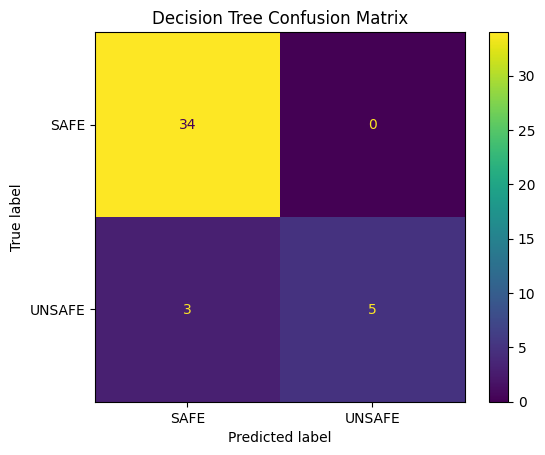

In [23]:
# ============================================
# STEP 8: ANALYZE DECISION TREE PREDICTIONS
# ============================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

print("=" * 50)
print("DECISION TREE CONFUSION MATRIX")
print("=" * 50)

print("\n              Predicted")
print("              SAFE  UNSAFE")
print(f"Actual SAFE    {cm_tree[0,0]:4}  {cm_tree[0,1]:6}")
print(f"Actual UNSAFE  {cm_tree[1,0]:4}  {cm_tree[1,1]:6}")

# Extract values
TN = cm_tree[0, 0]
FP = cm_tree[0, 1]
FN = cm_tree[1, 0]
TP = cm_tree[1, 1]

print("\nBreakdown:")
print(f"True Negatives  (SAFE → SAFE)     : {TN}")
print(f"False Positives (SAFE → UNSAFE)  : {FP}")
print(f"False Negatives (UNSAFE → SAFE)  : {FN}")
print(f"True Positives  (UNSAFE → UNSAFE): {TP}")

# Plot confusion matrix
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["SAFE", "UNSAFE"]
).plot()

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [25]:
# ============================================
# STEP 9: DECISION TREE TUNING
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

depths = [2, 3, 4, 5, 6]

tree_results = []

for depth in depths:

    # Create tree
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Metrics
    tree_results.append({
        "Max Depth": depth,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "UNSAFE Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Create results table
tree_tuning_results = pd.DataFrame(tree_results)

# Round values
metric_columns = [
    "Accuracy",
    "Precision",
    "UNSAFE Recall",
    "F1 Score"
]

tree_tuning_results[metric_columns] = (
    tree_tuning_results[metric_columns].round(4)
)

display(tree_tuning_results)

,Max Depth,Accuracy,Precision,UNSAFE Recall,F1 Score
0,2,0.9524,1.0,0.750,0.8571
1,3,0.9524,1.0,0.750,0.8571
2,4,0.9286,1.0,0.625,0.7692
3,5,0.9524,1.0,0.750,0.8571
4,6,0.9524,1.0,0.750,0.8571


In [26]:
# Total number of samples in each class

class_counts = final_dataset["label"].value_counts().sort_index()

print("Total samples in each class:")
print("--------------------------------")

for label, count in class_counts.items():
    if label == 0:
        print(f"SAFE   (0): {count} samples")
    elif label == 1:
        print(f"UNSAFE (1): {count} samples")

print("\nTotal samples:", len(final_dataset))

Total samples in each class:
--------------------------------
SAFE   (0): 167 samples
UNSAFE (1): 40 samples

Total samples: 207


In [41]:
# ============================================
# FINAL DECISION TREE - MAX DEPTH 2
# ============================================

from sklearn.tree import DecisionTreeClassifier

# Create final model
final_tree_model = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Train using the original final dataset split
final_tree_model.fit(
    X_train,
    y_train
)

# Predictions
y_pred_final_tree = final_tree_model.predict(
    X_test
)

print("=" * 60)
print("FINAL DECISION TREE")
print("=" * 60)

print("\nMax Depth:", final_tree_model.get_depth())
print("Number of Nodes:", final_tree_model.tree_.node_count)
print("Number of Leaves:", final_tree_model.get_n_leaves())

FINAL DECISION TREE

Max Depth: 2
Number of Nodes: 7
Number of Leaves: 4


In [42]:
# ============================================
# DISPLAY TREE RULES
# ============================================

from sklearn.tree import export_text

tree_rules = export_text(
    final_tree_model,
    feature_names=list(X_train.columns)
)

print("=" * 60)
print("DECISION TREE RULES")
print("=" * 60)

print(tree_rules)

DECISION TREE RULES
|--- y_rms <= 0.66
|   |--- x_rms <= 0.98
|   |   |--- class: 0
|   |--- x_rms >  0.98
|   |   |--- class: 1
|--- y_rms >  0.66
|   |--- x_range <= 1.73
|   |   |--- class: 1
|   |--- x_range >  1.73
|   |   |--- class: 0



In [43]:
# ============================================
# VERIFY FINAL DEPTH-2 DECISION TREE
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predictions
y_pred_final_tree = final_tree_model.predict(X_test)

# Metrics
accuracy = accuracy_score(y_test, y_pred_final_tree)
precision = precision_score(y_test, y_pred_final_tree, zero_division=0)
recall = recall_score(y_test, y_pred_final_tree, zero_division=0)
f1 = f1_score(y_test, y_pred_final_tree, zero_division=0)

print("=" * 60)
print("FINAL DECISION TREE - DEPTH 2")
print("=" * 60)

print(f"\nAccuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"UNSAFE Recall: {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final_tree))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_final_tree,
        target_names=[
            "SAFE",
            "UNSAFE"
        ],
        zero_division=0
    )
)

print("\nModel Complexity:")
print("Maximum depth :", final_tree_model.get_depth())
print("Number of nodes:", final_tree_model.tree_.node_count)
print("Number of leaves:", final_tree_model.get_n_leaves())

FINAL DECISION TREE - DEPTH 2

Accuracy : 0.9524
Precision: 1.0000
UNSAFE Recall: 0.7500
F1 Score : 0.8571

Confusion Matrix:
[[34  0]
 [ 2  6]]

Classification Report:
              precision    recall  f1-score   support

        SAFE       0.94      1.00      0.97        34
      UNSAFE       1.00      0.75      0.86         8

    accuracy                           0.95        42
   macro avg       0.97      0.88      0.91        42
weighted avg       0.96      0.95      0.95        42


Model Complexity:
Maximum depth : 2
Number of nodes: 7
Number of leaves: 4


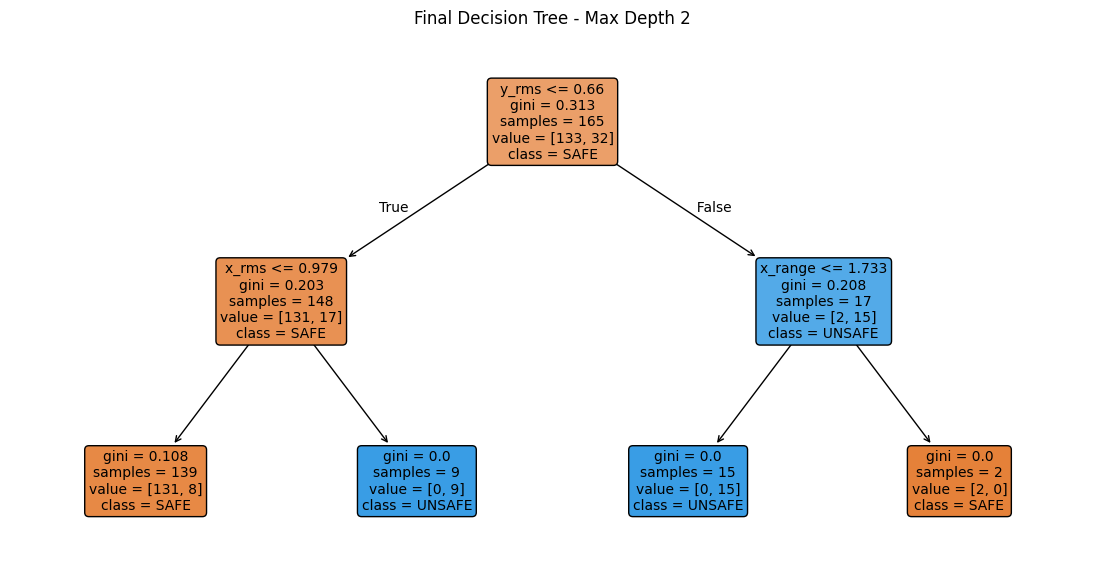

In [44]:
# ============================================
# VISUALIZE FINAL TREE
# ============================================

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

plot_tree(
    final_tree_model,
    feature_names=X_train.columns,
    class_names=["SAFE", "UNSAFE"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Final Decision Tree - Max Depth 2")
plt.show()

In [45]:
# ============================================
# STEP 11: EXTRACT TREE PARAMETERS
# ============================================

tree = final_tree_model.tree_

print("=" * 70)
print("DECISION TREE PARAMETERS FOR TINYML")
print("=" * 70)

print("\nTotal nodes :", tree.node_count)
print("Leaf nodes  :", final_tree_model.get_n_leaves())
print("Tree depth  :", final_tree_model.get_depth())

print("\n" + "-" * 70)

for node in range(tree.node_count):

    feature_index = tree.feature[node]
    threshold = tree.threshold[node]
    left_child = tree.children_left[node]
    right_child = tree.children_right[node]

    print(f"\nNode {node}")

    # Leaf node
    if feature_index == -2:
        class_id = tree.value[node][0].argmax()

        print("  Type      : LEAF")
        print("  Prediction:", class_id)

        if class_id == 0:
            print("  Meaning   : SAFE")
        else:
            print("  Meaning   : UNSAFE")

    # Decision node
    else:
        feature_name = X_train.columns[feature_index]

        print("  Type      : DECISION")
        print("  Feature   :", feature_name)
        print("  Threshold :", threshold)
        print("  Left node :", left_child)
        print("  Right node:", right_child)
        print(
            f"  Rule      : {feature_name} <= {threshold:.6f}"
        )

DECISION TREE PARAMETERS FOR TINYML

Total nodes : 7
Leaf nodes  : 4
Tree depth  : 2

----------------------------------------------------------------------

Node 0
  Type      : DECISION
  Feature   : y_rms
  Threshold : 0.659880667924881
  Left node : 1
  Right node: 4
  Rule      : y_rms <= 0.659881

Node 1
  Type      : DECISION
  Feature   : x_rms
  Threshold : 0.9793209731578827
  Left node : 2
  Right node: 3
  Rule      : x_rms <= 0.979321

Node 2
  Type      : LEAF
  Prediction: 0
  Meaning   : SAFE

Node 3
  Type      : LEAF
  Prediction: 1
  Meaning   : UNSAFE

Node 4
  Type      : DECISION
  Feature   : x_range
  Threshold : 1.7327193021774292
  Left node : 5
  Right node: 6
  Rule      : x_range <= 1.732719

Node 5
  Type      : LEAF
  Prediction: 1
  Meaning   : UNSAFE

Node 6
  Type      : LEAF
  Prediction: 0
  Meaning   : SAFE


In [51]:
# ============================================
# STEP 12: MANUAL TINYML INFERENCE
# ============================================

def tinyml_predict(x_rms, y_rms, x_range):
    """
    Lightweight implementation of the trained
    depth-2 Decision Tree.

    Returns:
        0 = SAFE
        1 = UNSAFE
    """

    # Root decision
    if y_rms <= 0.6598806679:

        # Left branch
        if x_rms <= 0.9793209732:
            return 0       # SAFE
        else:
            return 1       # UNSAFE

    else:

        # Right branch
        if x_range <= 1.7327193022:
            return 1       # UNSAFE
        else:
            return 0       # SAFE

In [52]:
# ============================================
# VERIFY MANUAL MODEL
# ============================================

manual_predictions = []

for _, row in X_test.iterrows():

    prediction = tinyml_predict(
        x_rms=row["x_rms"],
        y_rms=row["y_rms"],
        x_range=row["x_range"]
    )

    manual_predictions.append(prediction)

manual_predictions = np.array(manual_predictions)

# Compare with original Decision Tree
same_predictions = np.array_equal(
    manual_predictions,
    y_pred_final_tree
)

print("=" * 60)
print("TINYML MODEL VERIFICATION")
print("=" * 60)

print("\nScikit-Learn predictions:")
print(y_pred_final_tree)

print("\nManual TinyML predictions:")
print(manual_predictions)

print("\nPredictions identical:", same_predictions)

print(
    "\nNumber of differences:",
    np.sum(manual_predictions != y_pred_final_tree)
)

TINYML MODEL VERIFICATION

Scikit-Learn predictions:
[0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0]

Manual TinyML predictions:
[0 0 0 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0]

Predictions identical: True

Number of differences: 0


In [53]:
import numpy as np

# --------------------------------------------------
# STEP 13: TinyML Feature Extraction
# --------------------------------------------------

WINDOW_SIZE = 0.5       # seconds
STEP_SIZE = 0.25        # 50% overlap

tinyml_features = []

start_time = gyro_df["Time (s)"].iloc[0]
end_time = gyro_df["Time (s)"].iloc[-1]

window_start = start_time

while window_start + WINDOW_SIZE <= end_time:

    window_end = window_start + WINDOW_SIZE

    # Get data for this window
    window = gyro_df[
        (gyro_df["Time (s)"] >= window_start) &
        (gyro_df["Time (s)"] < window_end)
    ]

    if len(window) > 0:

        x = window["Gyroscope x (rad/s)"].values
        y = window["Gyroscope y (rad/s)"].values

        # Features required by the TinyML tree
        x_rms = np.sqrt(np.mean(x ** 2))
        y_rms = np.sqrt(np.mean(y ** 2))
        x_range = np.max(x) - np.min(x)

        tinyml_features.append([
            window_start,
            window_end,
            x_rms,
            y_rms,
            x_range
        ])

    window_start += STEP_SIZE


# Create dataframe
tinyml_df = pd.DataFrame(
    tinyml_features,
    columns=[
        "start_time",
        "end_time",
        "x_rms",
        "y_rms",
        "x_range"
    ]
)

print("Number of windows:", len(tinyml_df))
print("\nTinyML features:")
display(tinyml_df.head())

NameError: name 'gyro_df' is not defined

In [54]:
gyro_df = df.copy()

print(gyro_df.columns)

Index(['time', 'gyro_x', 'gyro_y'], dtype='object')


In [55]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 0.5
STEP_SIZE = 0.25

tinyml_features = []

start_time = gyro_df["Time (s)"].iloc[0]
end_time = gyro_df["Time (s)"].iloc[-1]

window_start = start_time

while window_start + WINDOW_SIZE <= end_time:

    window_end = window_start + WINDOW_SIZE

    window = gyro_df[
        (gyro_df["Time (s)"] >= window_start) &
        (gyro_df["Time (s)"] < window_end)
    ]

    if len(window) > 0:

        x = window["Gyroscope x (rad/s)"].values
        y = window["Gyroscope y (rad/s)"].values

        x_rms = np.sqrt(np.mean(x ** 2))
        y_rms = np.sqrt(np.mean(y ** 2))
        x_range = np.max(x) - np.min(x)

        tinyml_features.append([
            window_start,
            window_end,
            x_rms,
            y_rms,
            x_range
        ])

    window_start += STEP_SIZE

tinyml_df = pd.DataFrame(
    tinyml_features,
    columns=[
        "start_time",
        "end_time",
        "x_rms",
        "y_rms",
        "x_range"
    ]
)

print("Number of windows:", len(tinyml_df))
display(tinyml_df.head())

KeyError: 'Time (s)'

In [56]:
print(df.columns.tolist())

['time', 'gyro_x', 'gyro_y']


In [57]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# STEP 13: TinyML Feature Extraction
# --------------------------------------------------

WINDOW_SIZE = 0.5       # 0.5 second window
STEP_SIZE = 0.25        # 50% overlap

tinyml_features = []

start_time = df["time"].iloc[0]
end_time = df["time"].iloc[-1]

window_start = start_time

while window_start + WINDOW_SIZE <= end_time:

    window_end = window_start + WINDOW_SIZE

    # Select samples inside the current window
    window = df[
        (df["time"] >= window_start) &
        (df["time"] < window_end)
    ]

    if len(window) > 0:

        x = window["gyro_x"].values
        y = window["gyro_y"].values

        # Features used by our final Decision Tree
        x_rms = np.sqrt(np.mean(x ** 2))
        y_rms = np.sqrt(np.mean(y ** 2))
        x_range = np.max(x) - np.min(x)

        tinyml_features.append([
            window_start,
            window_end,
            x_rms,
            y_rms,
            x_range
        ])

    # Move forward by 0.25 seconds
    window_start += STEP_SIZE


# Create DataFrame
tinyml_df = pd.DataFrame(
    tinyml_features,
    columns=[
        "start_time",
        "end_time",
        "x_rms",
        "y_rms",
        "x_range"
    ]
)

print("Number of windows:", len(tinyml_df))
display(tinyml_df.head(10))

Number of windows: 285


,start_time,end_time,x_rms,y_rms,x_range
0,0.011484,0.511484,0.034452,0.157608,0.128893
1,0.261484,0.761484,0.061548,0.170976,0.208916
2,0.511484,1.011484,0.062675,0.103842,0.194255
3,0.761484,1.261484,0.030032,0.075287,0.089797
4,1.011484,1.511484,0.029079,0.106948,0.098349
5,1.261484,1.761484,0.051082,0.343029,0.234572
6,1.511484,2.011484,0.118335,0.572949,0.419054
7,1.761484,2.261484,0.121200,0.619853,0.419054
8,2.011484,2.511484,0.124484,0.469199,0.398284
9,2.261484,2.761484,0.139618,0.436839,0.503353


In [59]:
# --------------------------------------------------
# STEP 14: TinyML Prediction for Every Window
# --------------------------------------------------

def tinyml_predict(x_rms, y_rms, x_range):

    if y_rms <= 0.6598806679:

        if x_rms <= 0.9793209732:
            return 0      # SAFE
        else:
            return 1      # UNSAFE

    else:

        if x_range <= 1.7327193022:
            return 1      # UNSAFE
        else:
            return 0      # SAFE


# Apply the TinyML tree to every window
tinyml_df["prediction"] = tinyml_df.apply(
    lambda row: tinyml_predict(
        row["x_rms"],
        row["y_rms"],
        row["x_range"]
    ),
    axis=1
)

# Convert numbers to readable labels
tinyml_df["status"] = tinyml_df["prediction"].map({
    0: "SAFE",
    1: "UNSAFE"
})

# Display results
display(tinyml_df.head(20))

,start_time,end_time,x_rms,y_rms,x_range,prediction,status
0,0.011484,0.511484,0.034452,0.157608,0.128893,0,SAFE
1,0.261484,0.761484,0.061548,0.170976,0.208916,0,SAFE
2,0.511484,1.011484,0.062675,0.103842,0.194255,0,SAFE
3,0.761484,1.261484,0.030032,0.075287,0.089797,0,SAFE
4,1.011484,1.511484,0.029079,0.106948,0.098349,0,SAFE
5,1.261484,1.761484,0.051082,0.343029,0.234572,0,SAFE
6,1.511484,2.011484,0.118335,0.572949,0.419054,0,SAFE
7,1.761484,2.261484,0.121200,0.619853,0.419054,0,SAFE
8,2.011484,2.511484,0.124484,0.469199,0.398284,0,SAFE
9,2.261484,2.761484,0.139618,0.436839,0.503353,0,SAFE


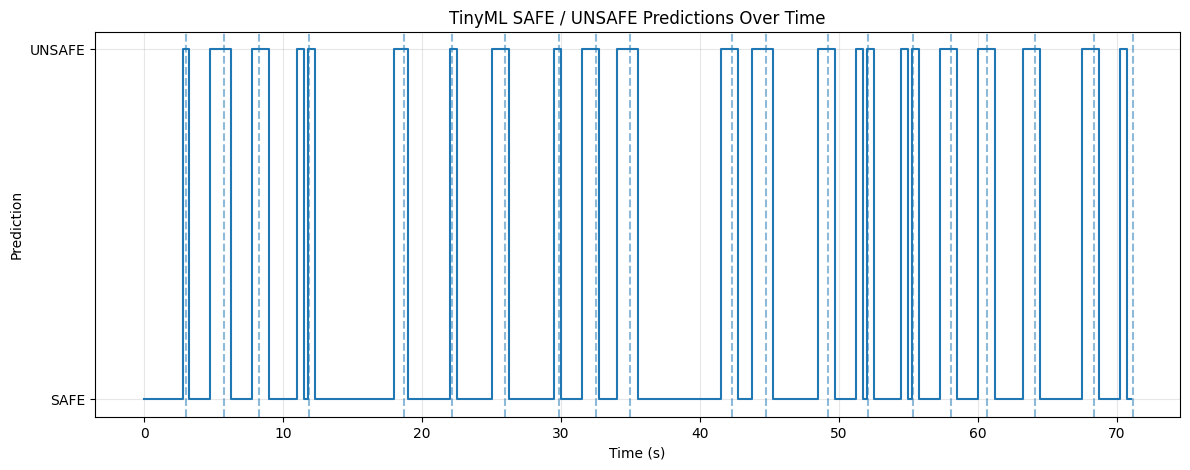

In [60]:
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 15: Visualize TinyML Predictions
# --------------------------------------------------

plt.figure(figsize=(14, 5))

# Plot predictions over time
plt.step(
    tinyml_df["start_time"],
    tinyml_df["prediction"],
    where="post"
)

# Mark the actual fall times
for fall_time in fall_times:
    plt.axvline(
        x=fall_time,
        linestyle="--",
        alpha=0.5
    )

plt.xlabel("Time (s)")
plt.ylabel("Prediction")
plt.yticks([0, 1], ["SAFE", "UNSAFE"])
plt.title("TinyML SAFE / UNSAFE Predictions Over Time")

plt.grid(True, alpha=0.3)
plt.show()

In [61]:
# --------------------------------------------------
# STEP 16: Evaluate TinyML Predictions
# --------------------------------------------------

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Start with all windows marked SAFE
tinyml_df["actual_label"] = 0

UNSAFE_DURATION = 0.5
POST_FALL_DURATION = 0.5

# Assign labels using the actual fall times
for fall_time in fall_times:

    # UNSAFE = 0.5 seconds BEFORE the fall
    unsafe_start = fall_time - UNSAFE_DURATION
    unsafe_end = fall_time

    unsafe_mask = (
        (tinyml_df["start_time"] < unsafe_end) &
        (tinyml_df["end_time"] > unsafe_start)
    )

    tinyml_df.loc[unsafe_mask, "actual_label"] = 1

    # Exclude the fall and immediate post-fall period
    post_start = fall_time
    post_end = fall_time + POST_FALL_DURATION

    post_mask = (
        (tinyml_df["start_time"] < post_end) &
        (tinyml_df["end_time"] > post_start)
    )

    tinyml_df.loc[post_mask, "actual_label"] = -1


# Keep only SAFE and UNSAFE windows
evaluation_df = tinyml_df[tinyml_df["actual_label"] != -1].copy()

# Actual and predicted labels
y_actual = evaluation_df["actual_label"]
y_pred = evaluation_df["prediction"]

# Metrics
accuracy = accuracy_score(y_actual, y_pred)
precision = precision_score(y_actual, y_pred, zero_division=0)
recall = recall_score(y_actual, y_pred, zero_division=0)
f1 = f1_score(y_actual, y_pred, zero_division=0)

print("TinyML Evaluation")
print("-----------------")
print("Windows evaluated:", len(evaluation_df))
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

TinyML Evaluation
-----------------
Windows evaluated: 207
Accuracy : 95.17 %
Precision: 100.0 %
Recall   : 75.0 %
F1 Score : 85.71 %

Confusion Matrix:
[[167   0]
 [ 10  30]]


In [63]:
import numpy as np

# --------------------------------------------------
# STEP 17: TinyML-style complete inference
# --------------------------------------------------

def tinyml_predict_window(gyro_x, gyro_y):

    # X RMS
    x_rms = np.sqrt(np.mean(gyro_x ** 2))

    # Y RMS
    y_rms = np.sqrt(np.mean(gyro_y ** 2))

    # X Range
    x_range = np.max(gyro_x) - np.min(gyro_x)

    # Decision Tree
    if y_rms <= 0.6598806679:

        if x_rms <= 0.9793209732:
            prediction = 0
        else:
            prediction = 1

    else:

        if x_range <= 1.7327193022:
            prediction = 1
        else:
            prediction = 0

    return prediction

In [64]:
# Take the first window
test_window = df[
    (df["time"] >= 0) &
    (df["time"] < 0.5)
]

x = test_window["gyro_x"].values
y = test_window["gyro_y"].values

prediction = tinyml_predict_window(x, y)

print("Prediction:", prediction)

if prediction == 0:
    print("SAFE")
else:
    print("UNSAFE / LIKELY TO FALL")

Prediction: 0
SAFE
